In [2]:
from importlib import reload
import TRECCASTeval as trec
import OpenSearchSimpleAPI as osearch
from retrieval_methods.LMD import LMD_Retrieval

import pprint as pp

osearch = reload(osearch)
trec = reload(trec)

lmd = LMD_Retrieval

opensearch = osearch.OSsimpleAPI()
test_bed = trec.ConvSearchEvaluation()
conv_topics = test_bed.train_topics


In [38]:
import torch

from transformers import AutoTokenizer, AutoModel, AutoConfig
from transformers import logging
logging.set_verbosity_warning()

import numpy as np
import pprint

from bertviz import model_view, head_view

# Get the interactive Tools for Matplotlib
%matplotlib notebook
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('ggplot')

# 
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

In [3]:
conv_topic_idx = 0

topic = conv_topics[conv_topic_idx]

turn = topic['turn'][7]
turn_id = turn['number']
utterance = turn['raw_utterance']
print(utterance)


result = lmd.retrieve_fun(opensearch,utterance,200)

What the difference between a PA and a nurse practitioner?
['MARCO_6311185', 'MARCO_7090806', 'MARCO_2849832', 'MARCO_3600884', 'MARCO_7514658', 'MARCO_8579371', 'MARCO_888704', 'MARCO_1908383', 'MARCO_168924', 'MARCO_3144856', 'MARCO_6312729', 'MARCO_4077804', 'MARCO_5407409', 'MARCO_7496118', 'MARCO_3984229', 'MARCO_1908384', 'MARCO_7446928', 'CAR_436ad602db45c2c05a6f1d2b9461f20e8400e60a', 'MARCO_5893872', 'MARCO_5699123', 'MARCO_3951096', 'MARCO_5673918', 'MARCO_6816116', 'MARCO_615449', 'CAR_a1abdc7279a2178f62a20792a69b6bdb95731eea', 'MARCO_1505116', 'MARCO_3984224', 'MARCO_6607048', 'MARCO_6244208', 'MARCO_2904127', 'MARCO_2307794', 'MARCO_4225982', 'MARCO_6311397', 'MARCO_4003509', 'MARCO_364098', 'MARCO_8407876', 'MARCO_4014355', 'MARCO_8716240', 'MARCO_2483667', 'MARCO_5787541', 'MARCO_291620', 'MARCO_7560829', 'MARCO_8503215', 'MARCO_3768527', 'MARCO_2596754', 'MARCO_1827628', 'MARCO_6607056', 'MARCO_6607051', 'MARCO_7342285', 'MARCO_8824030', 'MARCO_3860555', 'MARCO_4518595',

In [4]:
print(result)

                                              _id     _score  \
0                                   MARCO_6311185 -37.655107   
1                                   MARCO_7090806 -39.050118   
2                                   MARCO_2849832 -39.341187   
3                                   MARCO_7514658 -39.952613   
4                                   MARCO_3600884 -43.978987   
..                                            ...        ...   
195                                 MARCO_4847842 -69.825960   
196                                   MARCO_62926 -69.973198   
197                                 MARCO_5604435 -70.994448   
198  CAR_4d4e149f7b51d26af25203d7b69b6dae853f05b9 -73.007611   
199  CAR_eac4c13d758d330e97e60846c09b7df81eb1a404 -73.628529   

                                      _source.doc  
0                                   MARCO_6311185  
1                                   MARCO_7090806  
2                                   MARCO_2849832  
3                      

In [62]:
top_doc = result.iloc[1]
top_doc_body = opensearch.get_doc_body(top_doc._id)
print("TOP DOCUMENT:")
print("-" + top_doc_body)

bottom_doc = result.iloc[199]
bottom_doc_body = opensearch.get_doc_body(bottom_doc._id)
print("BOTTOM DOCUMENT:")
print("-" + bottom_doc_body)

TOP DOCUMENT:
-The Difference Between a Nurse Practitioner (NP) and a Physician Assistant (PA) As many patients know, people rarely see a medical doctor for routine physical examinations anymore. They are far more likely to have an appointment with a Nurse Practitioner (NP) or Physician Assistant (PA) who works in the practice.
BOTTOM DOCUMENT:
-There are performance differences and similarities between this class and other wheelchair classes. A 1999 study of discus throwers found that for F5 to F8 discus throwers, the upper arm tends to be near horizontal at the moment of release of the discus. F5 to F7 discus throwers have greater angular speed of the shoulder girdle during release of the discus than the lower number classes of F2 to F4. F5 and F8 discus throwers have less average angular forearm speed than F2 and F4 throwers.  F2 and F4 speed is caused by use of the elbow flexion to compensate for the shoulder flexion advantage of F5 to  F8 throwers. A study of javelin throwers in 2

In [64]:
from sentence_transformers import SentenceTransformer

# Load Cross-Encoder
cross_encoder_path = "cross-encoder/ms-marco-MiniLM-L-6-v2"
cross_encoder = SentenceTransformer(cross_encoder_path)

No sentence-transformers model found with name cross-encoder/ms-marco-MiniLM-L-6-v2. Creating a new one with mean pooling.


In [65]:
import numpy as np

from transformers import AutoTokenizer, AutoConfig, AutoModelForSequenceClassification
import torch
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
%matplotlib notebook
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('ggplot')

In [66]:
CLS_token = "[CLS]"
SEP_token = "[SEP]"

In [67]:
cross_encoder_tokenizer = AutoTokenizer.from_pretrained(cross_encoder_path)
cross_encoder_config = AutoConfig.from_pretrained(cross_encoder_path, output_hidden_states=True, output_attentions=True)
cross_encoder_model = AutoModelForSequenceClassification.from_pretrained(cross_encoder_path, config=cross_encoder_config)

In [68]:
cross_encoder_POS = cross_encoder_tokenizer(utterance,top_doc_body, return_tensors='pt', add_special_tokens=True, max_length = 512, padding=True, truncation = True)
cross_encoder_NEG = cross_encoder_tokenizer(utterance,bottom_doc_body, return_tensors='pt', add_special_tokens=True, max_length = 512, padding=True, truncation = True)

## FOR POSITIVE


In [69]:

print(cross_encoder_tokenizer.decode(cross_encoder_POS["input_ids"][0]))
input_ids_POS = cross_encoder_POS['input_ids']
input_ids_POS_list = input_ids_POS[0].tolist()
input_tokens_POS_list = cross_encoder_tokenizer.convert_ids_to_tokens(input_ids_POS_list)
print(input_tokens_POS_list)

[CLS] what the difference between a pa and a nurse practitioner? [SEP] the difference between a nurse practitioner ( np ) and a physician assistant ( pa ) as many patients know, people rarely see a medical doctor for routine physical examinations anymore. they are far more likely to have an appointment with a nurse practitioner ( np ) or physician assistant ( pa ) who works in the practice. [SEP]
['[CLS]', 'what', 'the', 'difference', 'between', 'a', 'pa', 'and', 'a', 'nurse', 'practitioner', '?', '[SEP]', 'the', 'difference', 'between', 'a', 'nurse', 'practitioner', '(', 'np', ')', 'and', 'a', 'physician', 'assistant', '(', 'pa', ')', 'as', 'many', 'patients', 'know', ',', 'people', 'rarely', 'see', 'a', 'medical', 'doctor', 'for', 'routine', 'physical', 'examinations', 'anymore', '.', 'they', 'are', 'far', 'more', 'likely', 'to', 'have', 'an', 'appointment', 'with', 'a', 'nurse', 'practitioner', '(', 'np', ')', 'or', 'physician', 'assistant', '(', 'pa', ')', 'who', 'works', 'in', 'th

In [70]:
res_POS = "\n".join("{} \t {}".format(x, y) for x, y in zip(input_ids_POS_list, input_tokens_POS_list))
print(res_POS)

101 	 [CLS]
2054 	 what
1996 	 the
4489 	 difference
2090 	 between
1037 	 a
6643 	 pa
1998 	 and
1037 	 a
6821 	 nurse
18742 	 practitioner
1029 	 ?
102 	 [SEP]
1996 	 the
4489 	 difference
2090 	 between
1037 	 a
6821 	 nurse
18742 	 practitioner
1006 	 (
27937 	 np
1007 	 )
1998 	 and
1037 	 a
7522 	 physician
3353 	 assistant
1006 	 (
6643 	 pa
1007 	 )
2004 	 as
2116 	 many
5022 	 patients
2113 	 know
1010 	 ,
2111 	 people
6524 	 rarely
2156 	 see
1037 	 a
2966 	 medical
3460 	 doctor
2005 	 for
9410 	 routine
3558 	 physical
14912 	 examinations
4902 	 anymore
1012 	 .
2027 	 they
2024 	 are
2521 	 far
2062 	 more
3497 	 likely
2000 	 to
2031 	 have
2019 	 an
6098 	 appointment
2007 	 with
1037 	 a
6821 	 nurse
18742 	 practitioner
1006 	 (
27937 	 np
1007 	 )
2030 	 or
7522 	 physician
3353 	 assistant
1006 	 (
6643 	 pa
1007 	 )
2040 	 who
2573 	 works
1999 	 in
1996 	 the
3218 	 practice
1012 	 .
102 	 [SEP]


In [71]:
with torch.no_grad():
    outputs = cross_encoder_model(**cross_encoder_POS)

attention = outputs.attentions
hidden_states = outputs.hidden_states


first_layer_embeddings = hidden_states[0][0]  # Shape: (num_tokens, hidden_dim)
last_layer_embeddings = hidden_states[-1][0]  # Shape: (num_tokens, hidden_dim)


first_10_tokens_first_layer = first_layer_embeddings[:10].detach().numpy()
first_10_tokens_last_layer = last_layer_embeddings[:10].detach().numpy()

In [72]:
first_layer_embeddings = hidden_states[0][0]  # Shape: (num_tokens, hidden_dim)
last_layer_embeddings = hidden_states[-1][0]  # Shape: (num_tokens, hidden_dim)

# Select first 10 token embeddings
first_10_tokens_first_layer = first_layer_embeddings[:10].detach().numpy()
first_10_tokens_last_layer = last_layer_embeddings[:10].detach().numpy()

In [73]:
def display_scatterplot(data, words):

    if data.shape[1] == 2:
        twodim = data
    else:
        pca = PCA()
        pca.fit(data)
        twodim = pca.transform(data)[:,:2]
    
    plt.style.use('default') # https://matplotlib.org/3.5.1/gallery/style_sheets/style_sheets_reference.html
    plt.figure(figsize=(6,6))
    plt.scatter(twodim[:,0], twodim[:,1], edgecolors='k', c='r')
    for word, (x,y) in zip(words, twodim):
        plt.text(x+0.05, y+0.05, word)

    return

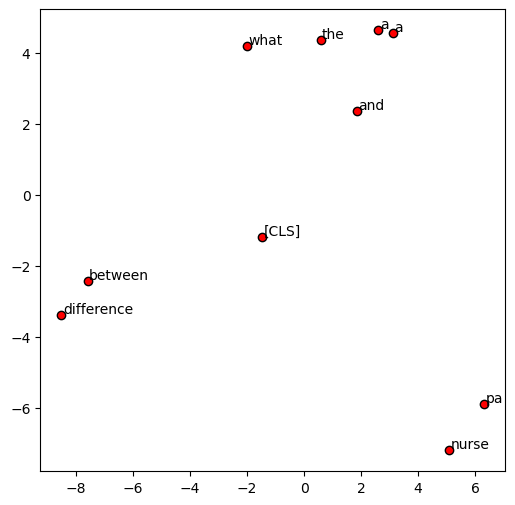

In [74]:
#Plot the token embeddings of the first-layer  
display_scatterplot(first_10_tokens_first_layer, input_tokens_POS_list[:10])

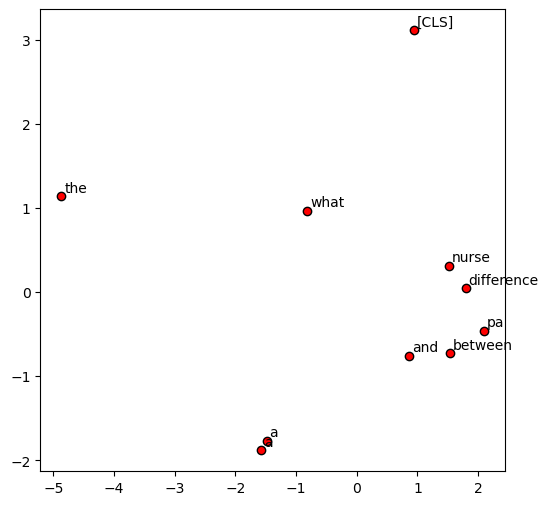

In [75]:
#Plot the token embeddings of the last-layer 
display_scatterplot(first_10_tokens_last_layer, input_tokens_POS_list[:10])

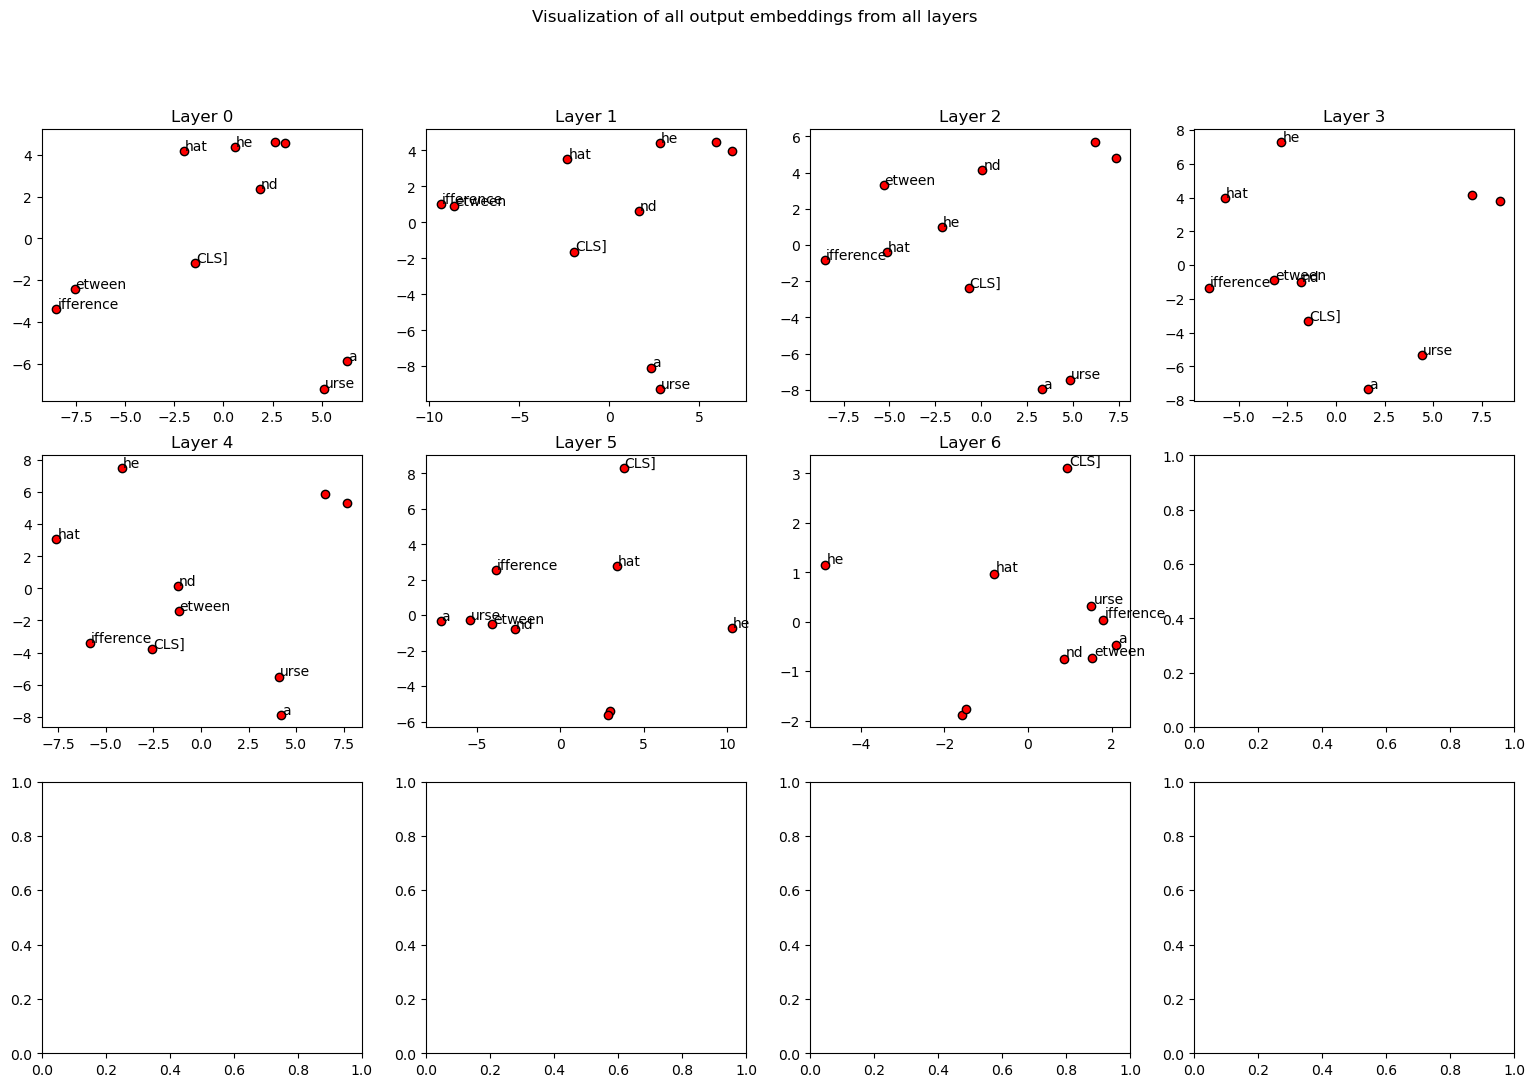

In [76]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

layer = 1

rows = 3
cols = 4
fig, ax_full = plt.subplots(rows, cols)
fig.set_figheight(rows*4)
fig.set_figwidth(cols*4+3)
plt.rcParams.update({'font.size': 6})


layer = 0
for r in range(rows):
    for c in range(cols):
        if layer >= len(hidden_states): 
            break
       
        ax = ax_full[r,c]
        
        plt.rcParams.update({'font.size': 10})
        current_hidden_state = hidden_states[layer][0].detach().numpy()

        current_hidden_state = current_hidden_state[:10]
        
        if current_hidden_state.shape[1] == 2:
            twodim = current_hidden_state
        else:
            twodim = PCA().fit_transform(current_hidden_state)[:,:2]

        plt.style.use('default') # https://matplotlib.org/3.5.1/gallery/style_sheets/style_sheets_reference.html
        im = ax.scatter(twodim[:,0], twodim[:,1], edgecolors='k', c='r')
        for word, (x,y) in zip(input_tokens_POS_list, twodim):
            ax.text(x+0.05, y+0.05, word[1:])
        
        # Show all ticks and label them with the respective list entries
        ax.set_title("Layer " + str(layer))
            
        # Loop over data dimensions and create text annotations.
        layer = layer + 1

fig.suptitle("Visualization of all output embeddings from all layers")
plt.show()

In [77]:
#SIMILARITY

with torch.no_grad():
    outputs = cross_encoder_model(**cross_encoder_POS)

attention = outputs.attentions
hidden_states = outputs.hidden_states


first_layer_embeddings = hidden_states[0][0]  # Shape: (num_tokens, hidden_dim)
last_layer_embeddings = hidden_states[-1][0]  # Shape: (num_tokens, hidden_dim)


first_10_tokens_first_layer = first_layer_embeddings[:10].detach().numpy()
first_10_tokens_last_layer = last_layer_embeddings[:10].detach().numpy()

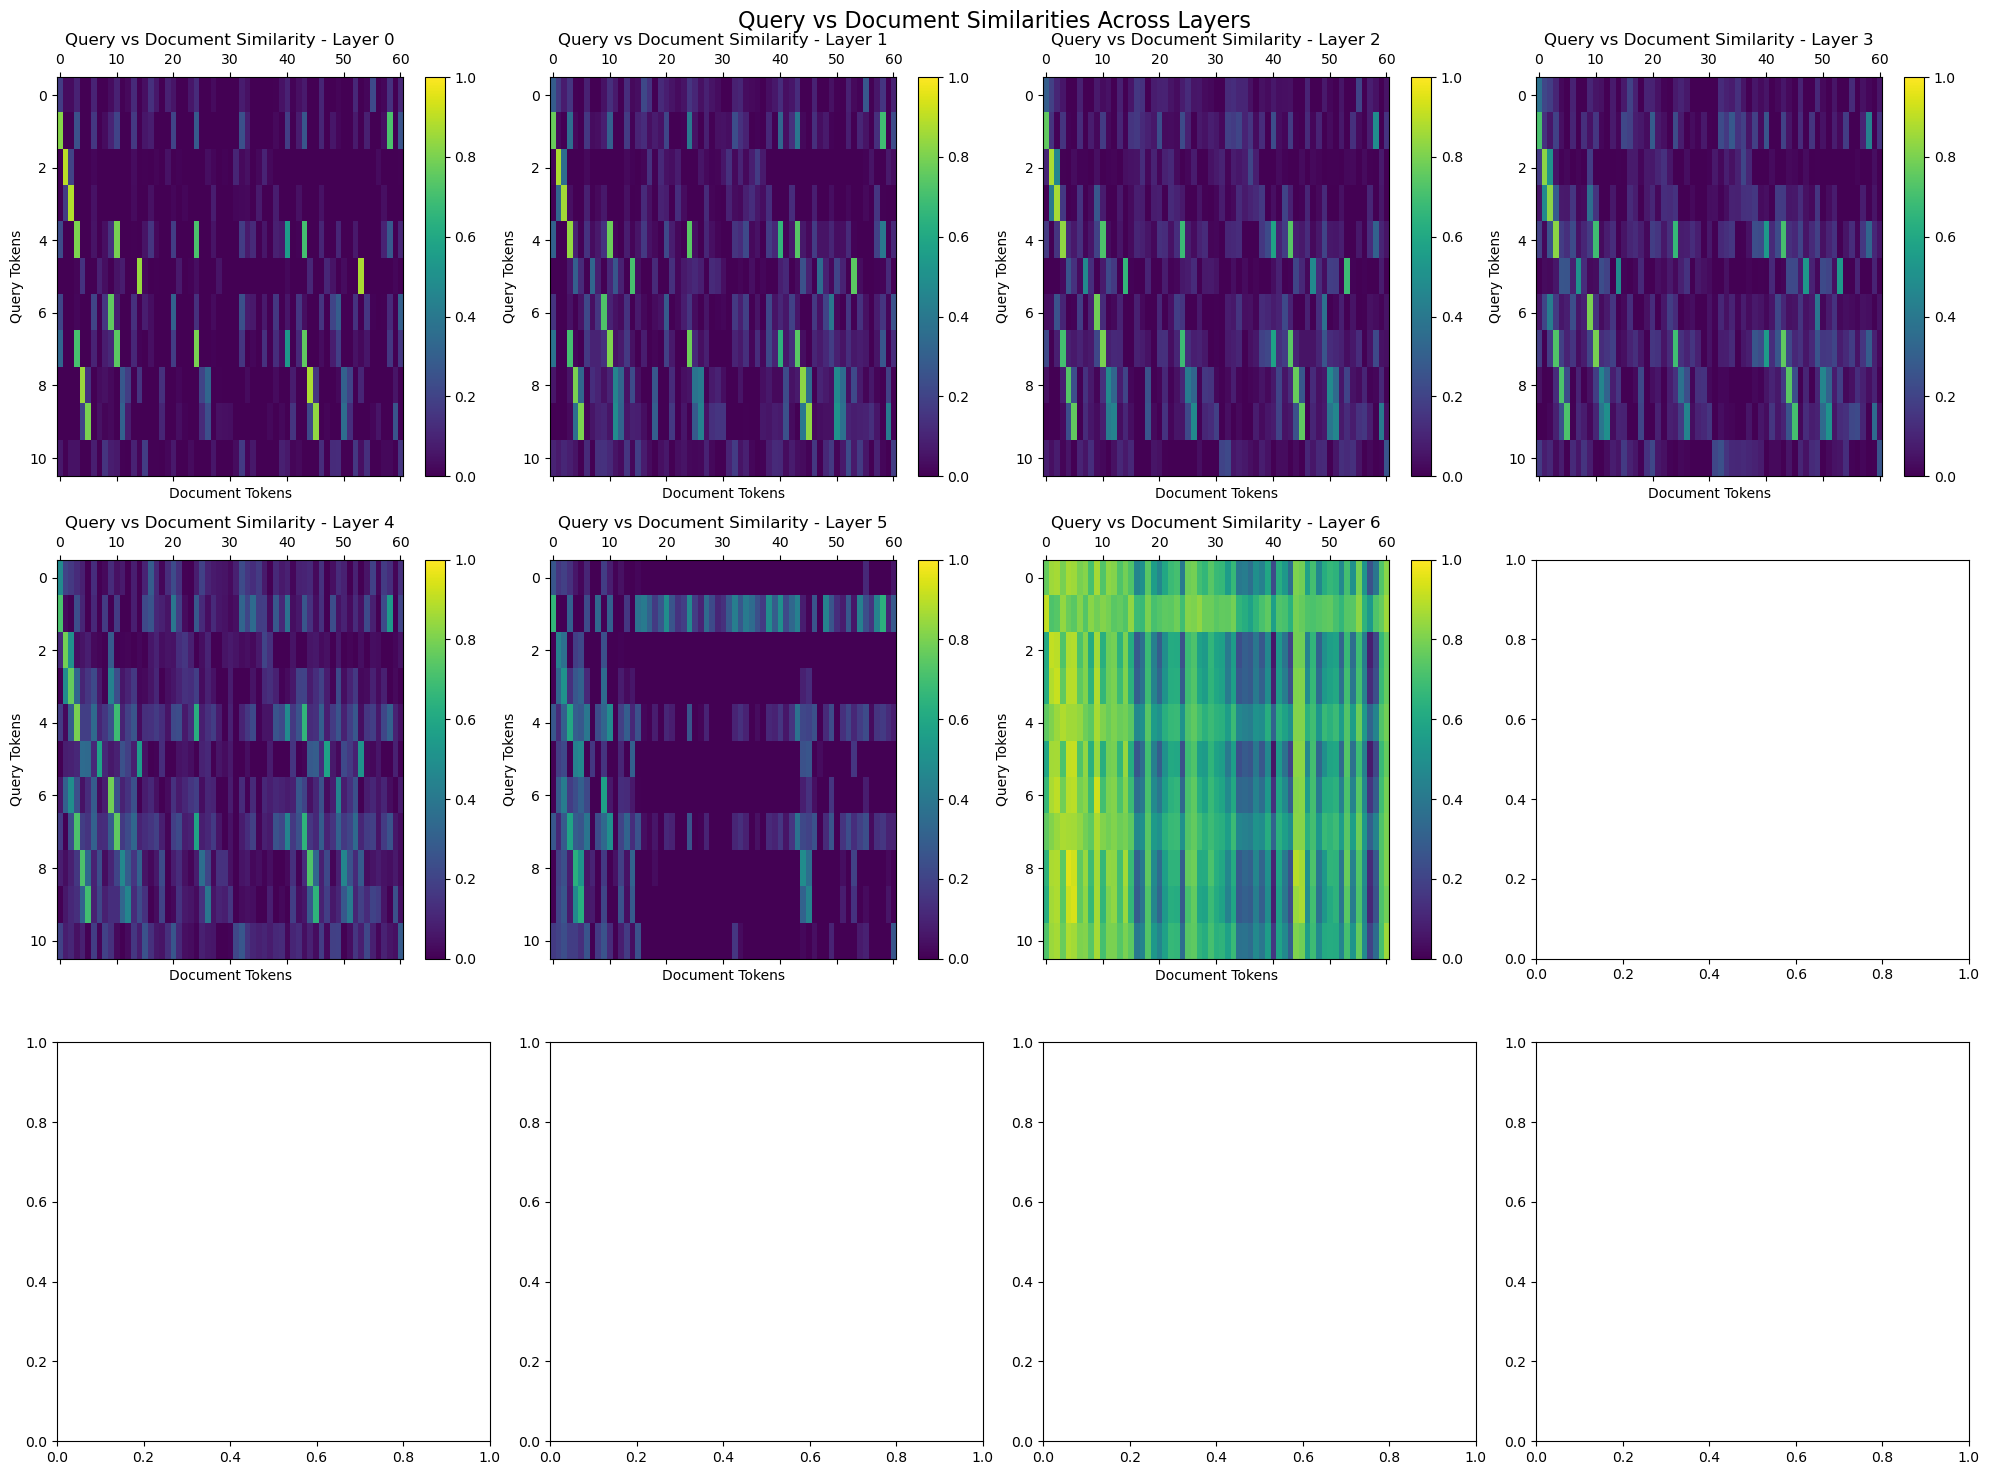

In [78]:

# Determine indices of query and document tokens
sep_token_id = cross_encoder_tokenizer.sep_token_id  # Get the ID of [SEP]
input_ids_POS_list = input_ids_POS[0].tolist()    

query_indices = range(1, input_ids_POS_list.index(sep_token_id))  

# Document tokens are between the first [SEP] and the second [SEP]
doc_indices = range(input_ids_POS_list.index(sep_token_id) + 1, len(input_ids_POS_list) - 1)

from sklearn.metrics.pairwise import cosine_similarity
#import numpy as np

similarities = []

for layer in range(len(hidden_states)):
    layer_embeddings = hidden_states[layer][0].detach().numpy()
    query_embeddings = layer_embeddings[query_indices]
    doc_embeddings = layer_embeddings[doc_indices]

    # Compute similarity matrix
    similarity_matrix = cosine_similarity(query_embeddings, doc_embeddings)
    similarities.append(similarity_matrix)


import matplotlib.pyplot as plt
import numpy as np

# Assuming similarities is a list of similarity matrices (one for each layer)
rows, cols = 3, 4  # Adjust based on the number of layers
fig, ax_full = plt.subplots(rows, cols, figsize=(20, 15))

layer = 0
for r in range(rows):
    for c in range(cols):
        if layer >= len(similarities):  # Avoid indexing beyond available layers
            break
        
        ax = ax_full[r, c]
        similarity_matrix = similarities[layer]
        
        # Plot similarity matrix using matshow (alternative to heatmap)
        cax = ax.matshow(similarity_matrix, cmap="viridis", aspect='auto', vmin=0, vmax=1)

        ax.set_title(f"Query vs Document Similarity - Layer {layer}")
        ax.set_xlabel("Document Tokens")
        ax.set_ylabel("Query Tokens")
        
        # Add colorbar to the side
        fig.colorbar(cax, ax=ax)

        layer += 1

plt.suptitle("Query vs Document Similarities Across Layers", fontsize=16)
plt.tight_layout()
plt.show()

In [79]:
def call_html():
  import IPython
  display(IPython.core.display.HTML('''
        <script src="/static/components/requirejs/require.js"></script>
        <script>
          requirejs.config({
            paths: {
              base: '/static/base',
              "d3": "https://cdnjs.cloudflare.com/ajax/libs/d3/5.7.0/d3.min",
              jquery: '//ajax.googleapis.com/ajax/libs/jquery/2.0.0/jquery.min',
            },
          });
        </script>
        '''))

In [48]:
call_html()
head_view(attention, input_tokens_POS_list)

ValueError: Attention has 146 positions, while number of tokens is 10 for tokens: [CLS] what the difference between a pa and a nurse

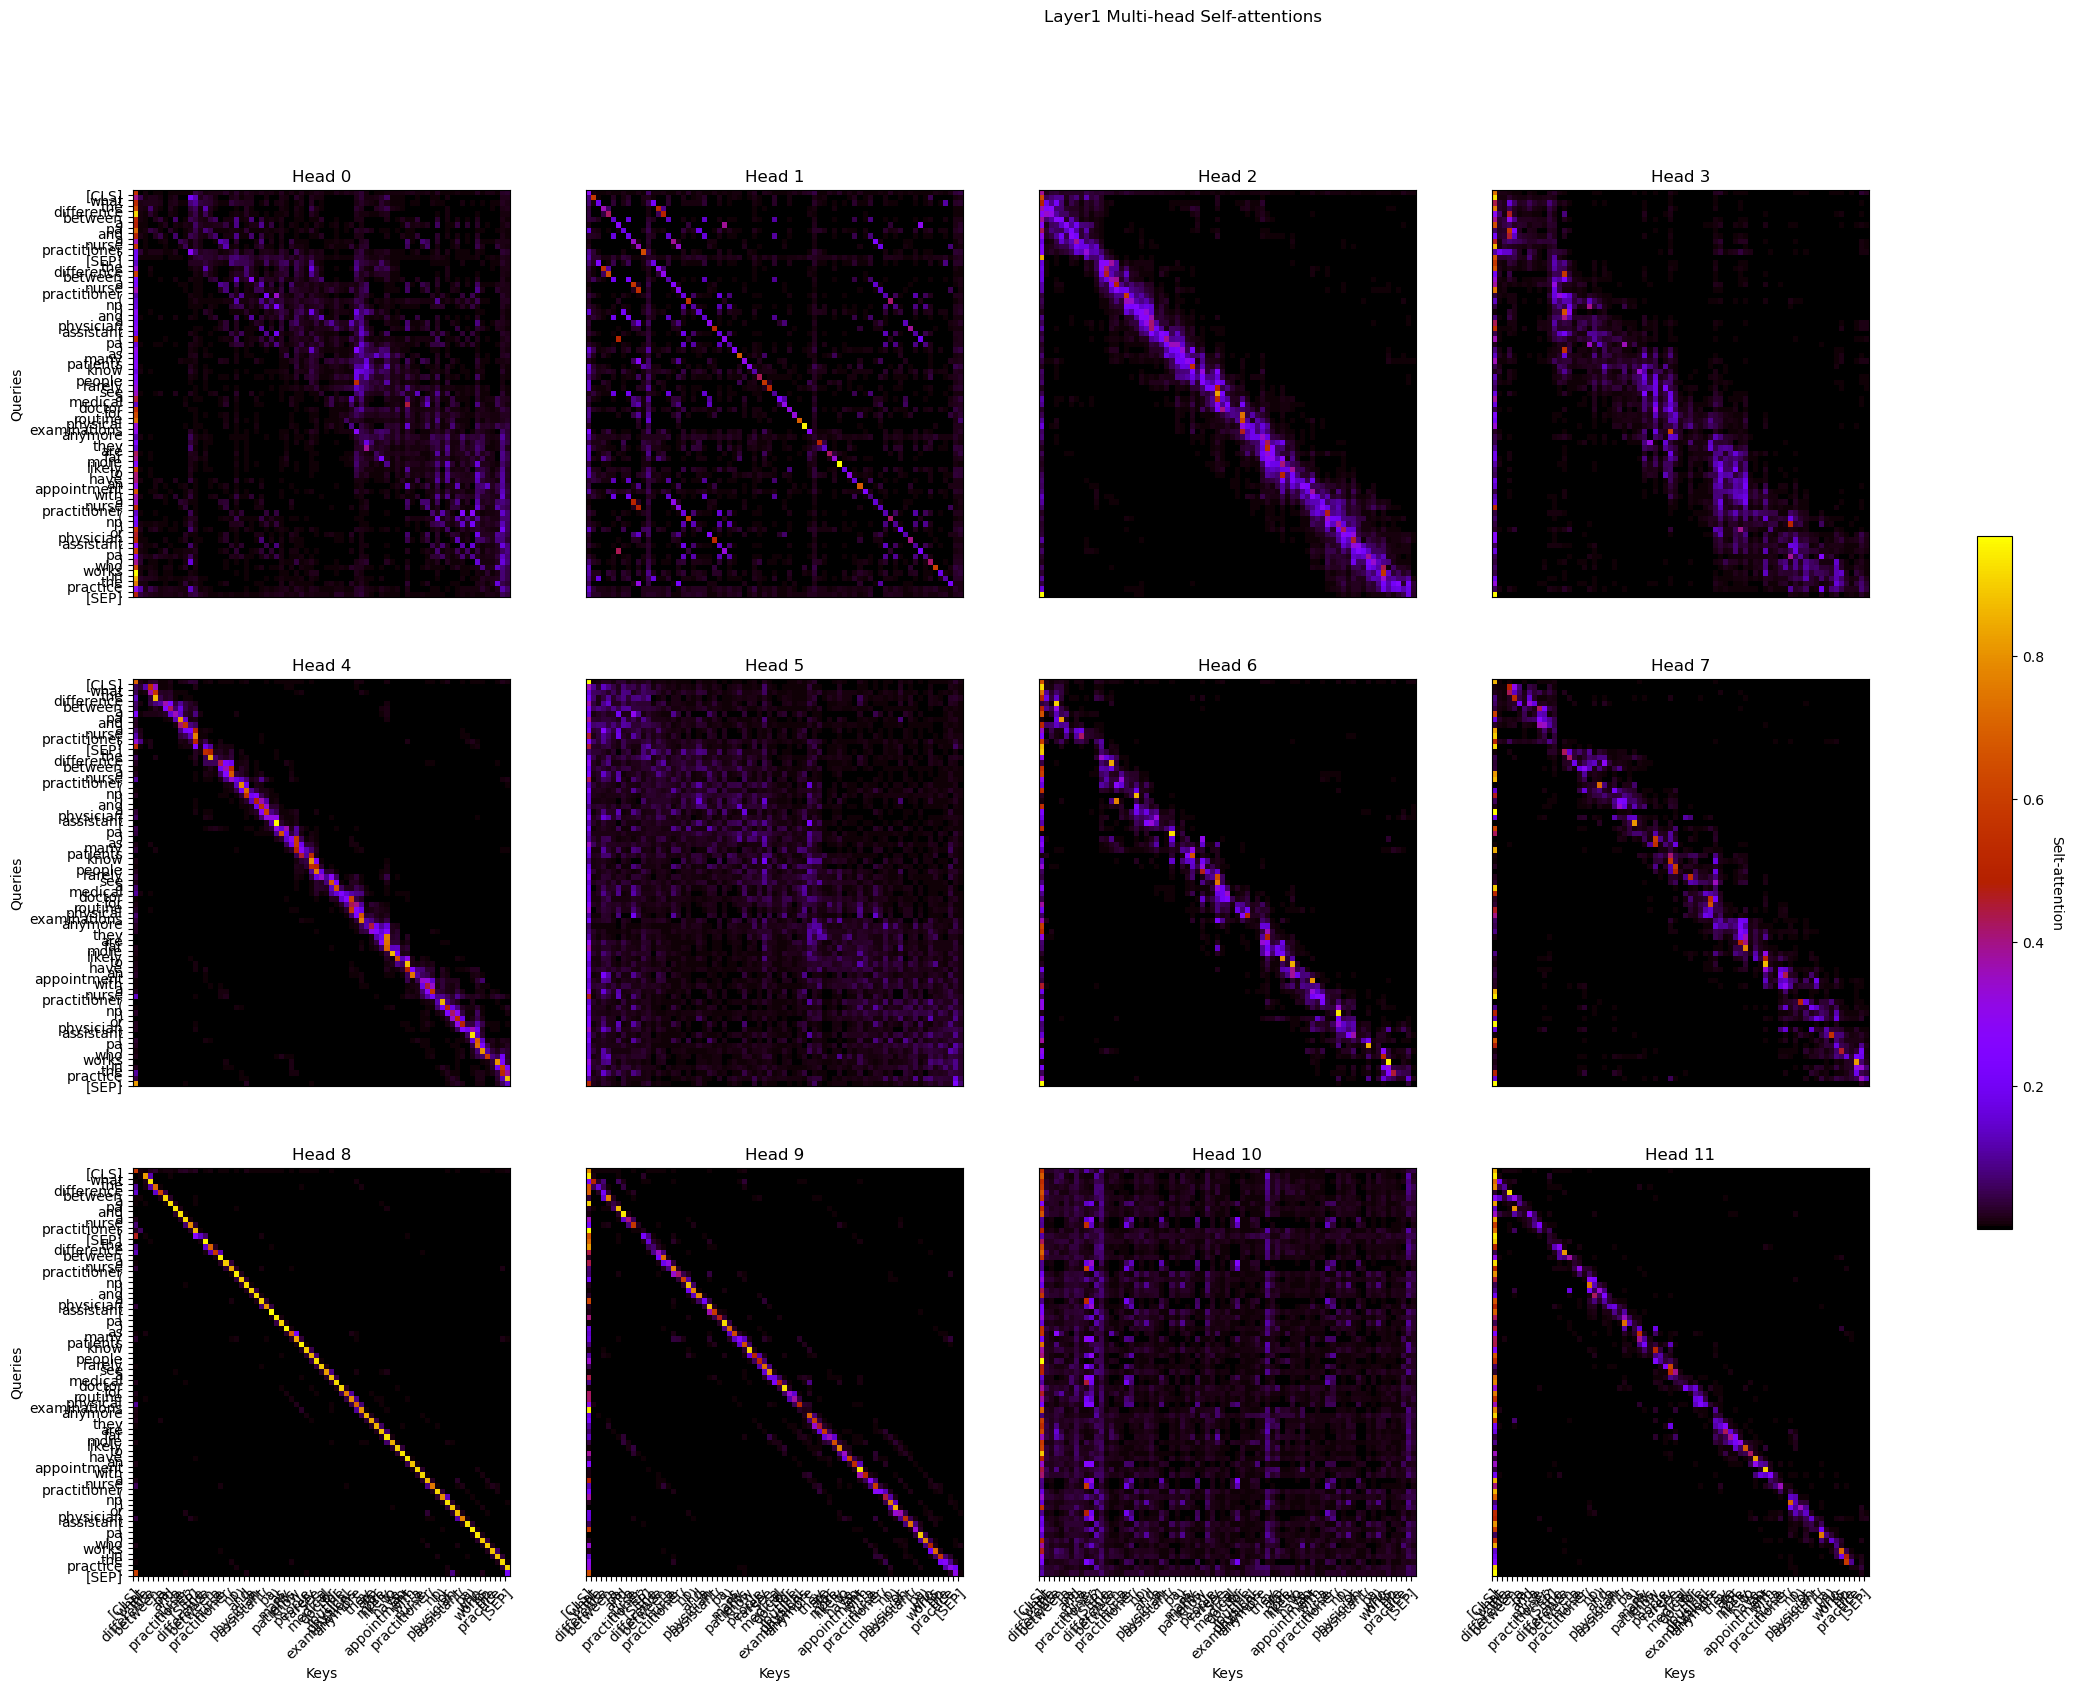

In [82]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

layer = 1

rows = 3
cols = 4
fig, ax_full = plt.subplots(rows, cols)
fig.set_figheight(rows*6)
fig.set_figwidth(cols*6+4)
plt.rcParams.update({'font.size': 10})


j = 0
for r in range(rows):
    for c in range(cols):
        
        ax = ax_full[r,c]
        
        sattention = attention[layer][0][j].numpy()
        sattention = np.flip(sattention, 0)
        
        plt.rcParams.update({'font.size': 10})

        im = ax.pcolormesh(sattention, cmap='gnuplot')

        # Show all ticks and label them with the respective list entries
        ax.set_title("Head " + str(j))
        ax.set_yticks(np.arange(len(input_tokens_POS_list)))
        if c == 0:
            ax.set_yticklabels(reversed(input_tokens_POS_list))
            ax.set_ylabel("Queries")
        else:
            ax.set_yticks([])

        ax.set_xticks(np.arange(len(input_tokens_POS_list)))
        if r == rows-1:
            ax.set_xticklabels(input_tokens_POS_list)
            ax.set_xlabel("Keys")
            
            # Rotate the tick labels and set their alignment.
            plt.setp(ax.get_xticklabels(), rotation=45, ha="right",
                     rotation_mode="anchor")
        else:
            ax.set_xticks([])

            
        # Loop over data dimensions and create text annotations.
        j = j + 1

fig.suptitle("Layer" + str(layer) + " Multi-head Self-attentions")
cbar = fig.colorbar(im, ax=ax_full, location='right', shrink=0.5)
cbar.ax.set_ylabel("Selt-attention", rotation=-90, va="bottom")

plt.show()


## FOR NEGATIVE